<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/07_ML_kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# k-nearest neighbour (k-NN)


---


The k-Nearest Neighbours (k-NN) algorithm can be used for both classification and regression. Unlike many machine learning methods, k-NN does not learn a set of model parameters during training. Instead, it makes predictions by looking at the training samples that are closest to a new data point.

For classification, the predicted class is usually determined by a majority vote among the nearest neighbours. For regression, the prediction is typically based on the average value of the nearest neighbours.

## Finding the nearest neighbours

To make a prediction, k-NN first finds the `k` training samples that are closest to the new data point in the feature space.

The distance between two samples can be calculated in different ways. Euclidean distance is commonly used, although other measures, such as Manhattan distance, can also be used.

## Choosing k

The value of `k` determines how many neighbouring samples are considered when making a prediction.

Suppose we have two classes, represented by △ and □, and we want to classify a new point represented by `?`.

- With `k = 1`, only the closest neighbour is considered. If that neighbour belongs to class △, the new point is classified as △.
- With `k = 3`, the three closest neighbours are considered and the majority class is used. If two of those neighbours belong to class □, the new point is classified as □.

Changing `k` can therefore change the predicted class. A small value of `k` makes the prediction depend strongly on nearby individual samples, while a larger value considers a wider neighbourhood.

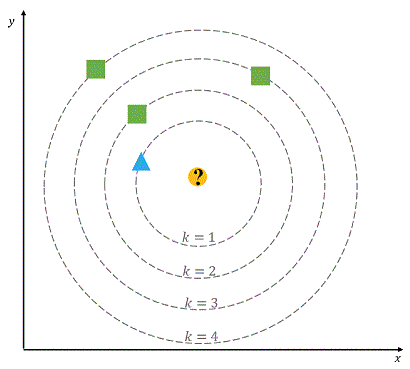


k-NN has a few useful advantages, but it also comes with some limitations.

**Advantages**

-  k-NN is straightforward to implement and does not require a separate model-training stage.
- The method does not assume a particular relationship or distribution in the data.
-  Predictions are made directly from the stored training samples.

**Disadvantages**

- k-NN may need to calculate the distance from a new sample to many or all training samples, which can become expensive for large datasets.
- The training data must be stored so that it can be used when making predictions.
-  Different values of `k` can produce different predictions.
-  Features with larger numerical ranges can dominate the distance calculation if the data is not scaled appropriately.

In this exercise, we will apply a k-NN classifier to the Iris dataset and examine how the choice of `k` affects its performance.

In [1]:
import numpy as np
import math
from sklearn import preprocessing
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import datasets

In [2]:
iris_data = datasets.load_iris()

In [3]:
# Function to divide the data into training and testing

import random
random.seed(22)
def separate_data():
    train_A = iris_dataset[0:40]
    test_A = iris_dataset[40:50]
    train_B = iris_dataset[50:90]
    test_B = iris_dataset[90:100]
    train_C = iris_dataset[100:140]
    test_C = iris_dataset[140:150]
    train = np.concatenate((train_A,train_B,train_C))
    test =  np.concatenate((test_A,test_B,test_C))
    return train,test

iris_dataset = np.column_stack((iris_data.data,iris_data.target.T)) #Join X and Y
iris_dataset = list(iris_dataset)
random.shuffle(iris_dataset)

Filetrain, Filetest = separate_data()

X_train = np.array([i[:4] for i in Filetrain])
y_train = np.array([i[4] for i in Filetrain])
X_test = np.array([i[:4] for i in Filetest])
y_test = np.array([i[4] for i in Filetest])

In [4]:
def distance(p1, p2):
    squared_difference = 0.0
    for i in range(len(p1)):
        squared_difference += (p1[i] - p2[i])**2
    final_distance = squared_difference ** 0.5
    return final_distance

In [5]:
def fit(test_sample, training_set, training_labels, k):

    distances = []

    # Computing the distances for all data points with respect to test sample

    for i in range(len(training_set)):
        distance_to_point = distance(test_sample, training_set[i])
        distances.append([distance_to_point, training_set[i], training_labels[i]])
    # sort the distances
    distances.sort(key = lambda x : x[0])

    # Find the k nearest neighbours according to the distances
    k_nearest_neighbours = distances[0:k]

    # Getting class with majority voting
    label_counts = {}
    for i in range(0, k):
        closest_label = k_nearest_neighbours[i][2]

        if (closest_label in label_counts) == True:
            label_counts[closest_label] += 1
        else:
            label_counts[closest_label] = 1

    labelCounts = list(label_counts.values())
    classes = list(label_counts.keys())
    y_pred = classes[labelCounts.index(max(labelCounts))]

    return (k_nearest_neighbours, y_pred)

In [6]:
k = 3
print(f'Test sample predictions for k = {k} \t')
print('*********************************')
for i in range(len(X_test)):
    neighbours, pred_label = fit(X_test[i], X_train, y_train, k)
    if (pred_label == y_test[i]):
        print(f'test sample: {X_test[i]} \t',
          f'predicted label: {pred_label} \t', f'true label: {y_test[i]} \t', "Correctly classified")
    else:

        print(f'test sample: {X_test[i]} \t',
          f'predicted label: {pred_label} \t', f'true label: {y_test[i]} \t', "Misclassified")

Test sample predictions for k = 3 	
*********************************
test sample: [5.1 3.8 1.9 0.4] 	 predicted label: 0.0 	 true label: 0.0 	 Correctly classified
test sample: [6.3 2.3 4.4 1.3] 	 predicted label: 1.0 	 true label: 1.0 	 Correctly classified
test sample: [6.5 3.  5.5 1.8] 	 predicted label: 2.0 	 true label: 2.0 	 Correctly classified
test sample: [6.7 2.5 5.8 1.8] 	 predicted label: 2.0 	 true label: 2.0 	 Correctly classified
test sample: [6.2 2.9 4.3 1.3] 	 predicted label: 1.0 	 true label: 1.0 	 Correctly classified
test sample: [7.2 3.2 6.  1.8] 	 predicted label: 2.0 	 true label: 2.0 	 Correctly classified
test sample: [4.4 2.9 1.4 0.2] 	 predicted label: 0.0 	 true label: 0.0 	 Correctly classified
test sample: [6.1 2.9 4.7 1.4] 	 predicted label: 1.0 	 true label: 1.0 	 Correctly classified
test sample: [7.1 3.  5.9 2.1] 	 predicted label: 2.0 	 true label: 2.0 	 Correctly classified
test sample: [4.7 3.2 1.3 0.2] 	 predicted label: 0.0 	 true label: 0.0 	 C

In [7]:
def accuracy(pred_label, true_label):
    TP = 0
    for i in range(len(pred_label)):
        if(pred_label[i] == true_label[i]):
            TP += 1

    accuracy = (TP / len(pred_label))
    return accuracy

For k = 1, Accuracy 0.9333333333333333 %
For k = 3, Accuracy 0.9666666666666667 %
For k = 5, Accuracy 0.9666666666666667 %
For k = 7, Accuracy 0.9666666666666667 %
For k = 9, Accuracy 0.9666666666666667 %
For k = 11, Accuracy 0.9666666666666667 %
For k = 13, Accuracy 1.0 %
For k = 15, Accuracy 1.0 %
For k = 17, Accuracy 0.9666666666666667 %
For k = 19, Accuracy 0.9666666666666667 %
For k = 21, Accuracy 0.9666666666666667 %
For k = 23, Accuracy 0.9666666666666667 %
For k = 25, Accuracy 0.9666666666666667 %
For k = 27, Accuracy 0.9666666666666667 %
For k = 29, Accuracy 0.9666666666666667 %


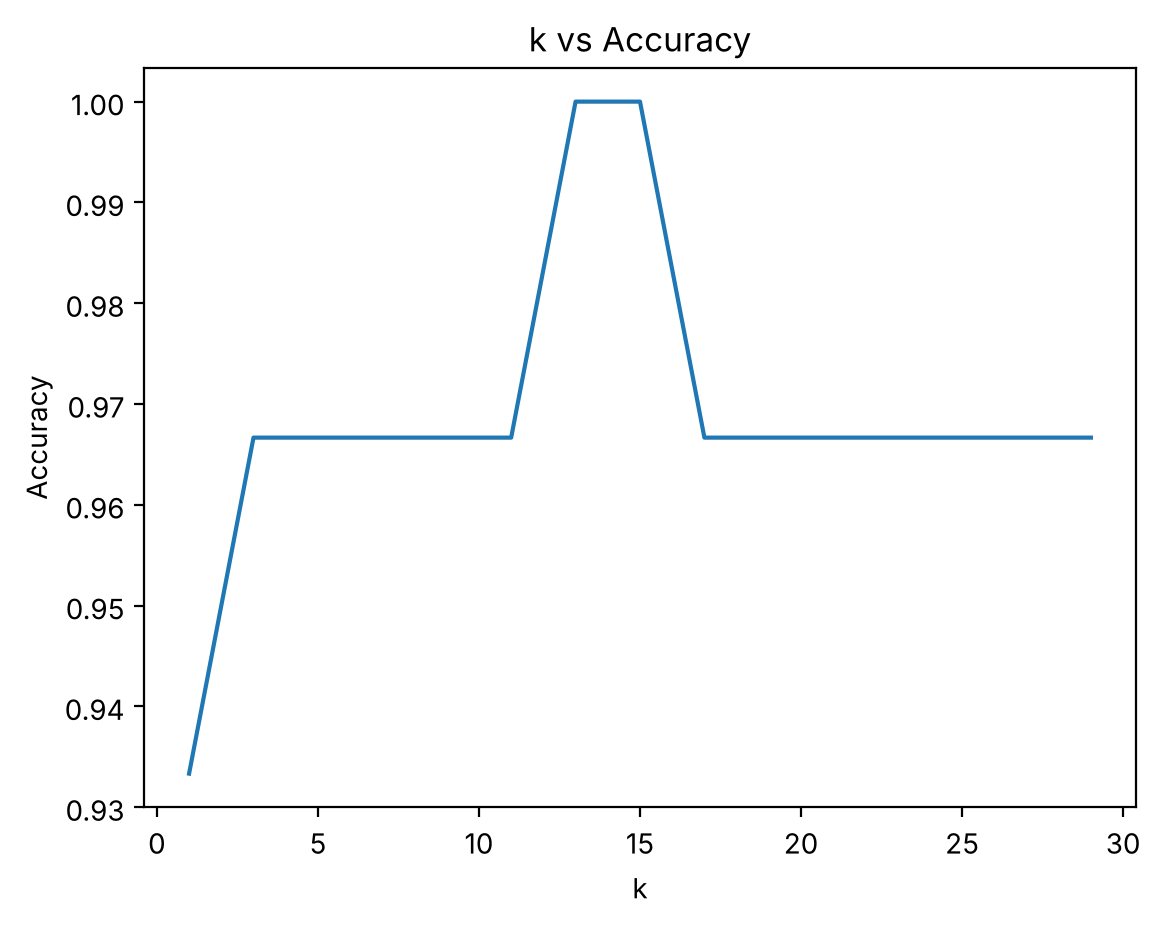

In [8]:
accuracy_list = []
k_list = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29]

for k in k_list:
    y_pred = []
    for test_instance in X_test:
        neighbours, pred_label = fit(test_instance, X_train, y_train, k)
        y_pred.append(pred_label)
    acc = accuracy(y_pred, y_test)
    print("For k = {}, Accuracy {} %".format(k,acc))

    accuracy_list.append(acc)
plt.plot(k_list, accuracy_list)

plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('k vs Accuracy')

plt.show()

In [9]:
from matplotlib.colors import ListedColormap
h = .02  # step size in the mesh

# Create color maps
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

def decision_boundary(k):
    # For better data visulaisation we considered the first two features (petal length and sepal length)
    # in the decision boundary plot.
    X = np.concatenate((X_train, X_test))
    X = X[:, :2]
    y = np.concatenate((y_train, y_test))

    # Plot the decision boundary. For that, we will assign a color to each
    # point in the mesh [x_min, x_max]x[y_min, y_max].
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = np.c_[xx.ravel(), yy.ravel()]

    y_preds = []

    for item in Z:
        neighbours, pred_label = fit(item, X, y, k)
        y_preds.append(pred_label)

     # Put the result into a color plot
    y_preds = np.asarray(y_preds)
    y_preds = y_preds.reshape(xx.shape)

    plt.figure()
    plt.pcolormesh(xx, yy, y_preds, cmap=cmap_light)

    # Plot also the training points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title("Decision boundary for k = {0}".format(k))

    plt.show()

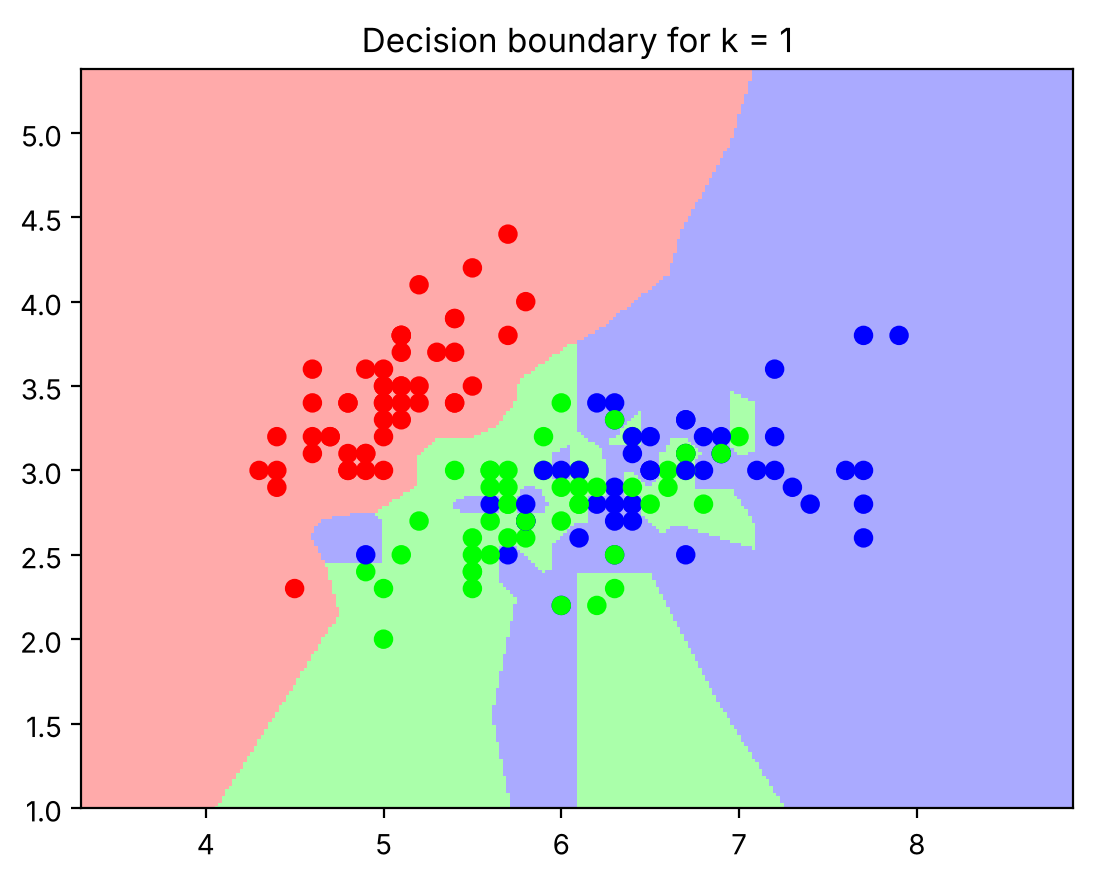

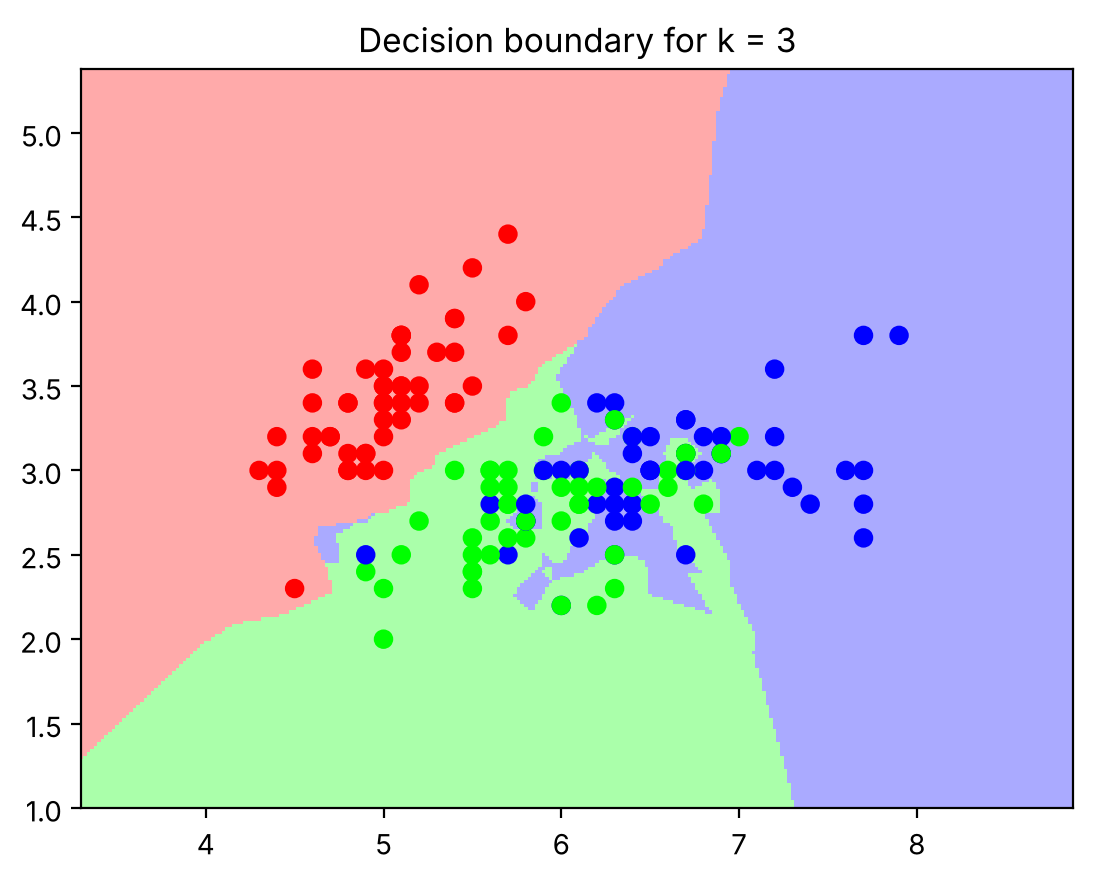

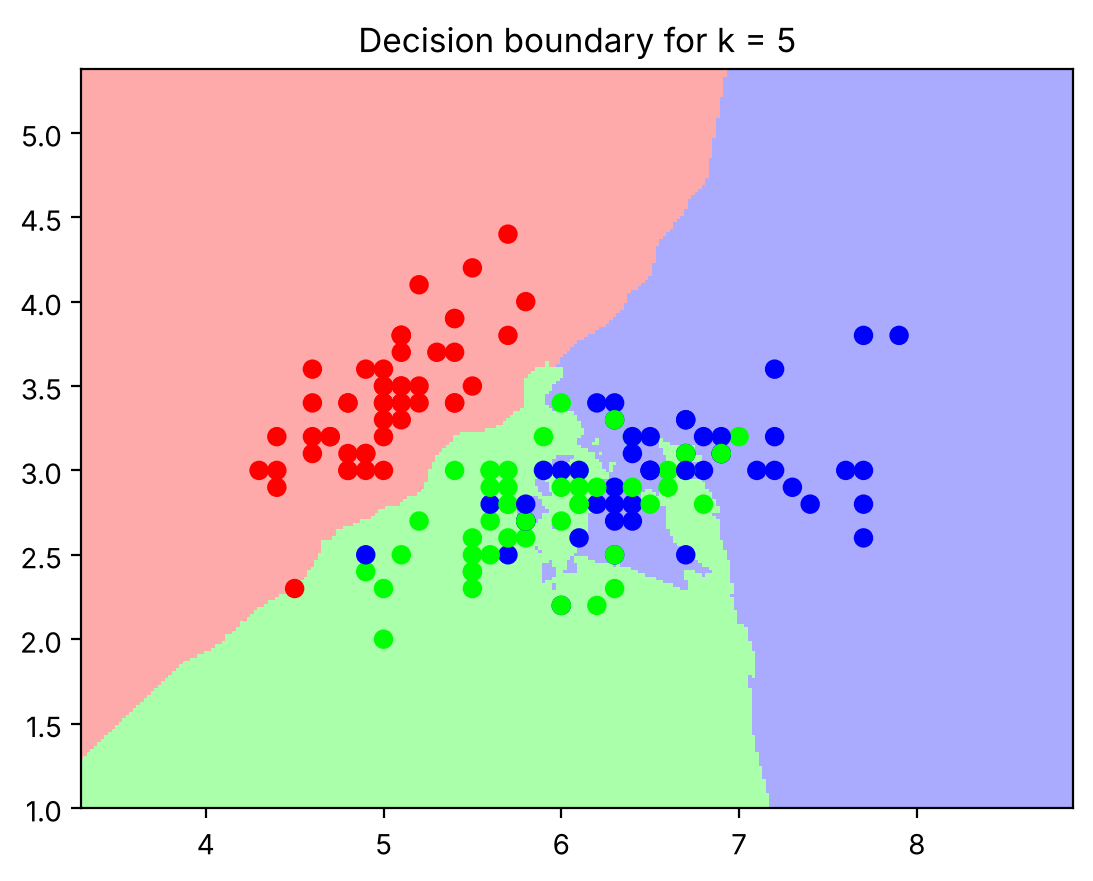

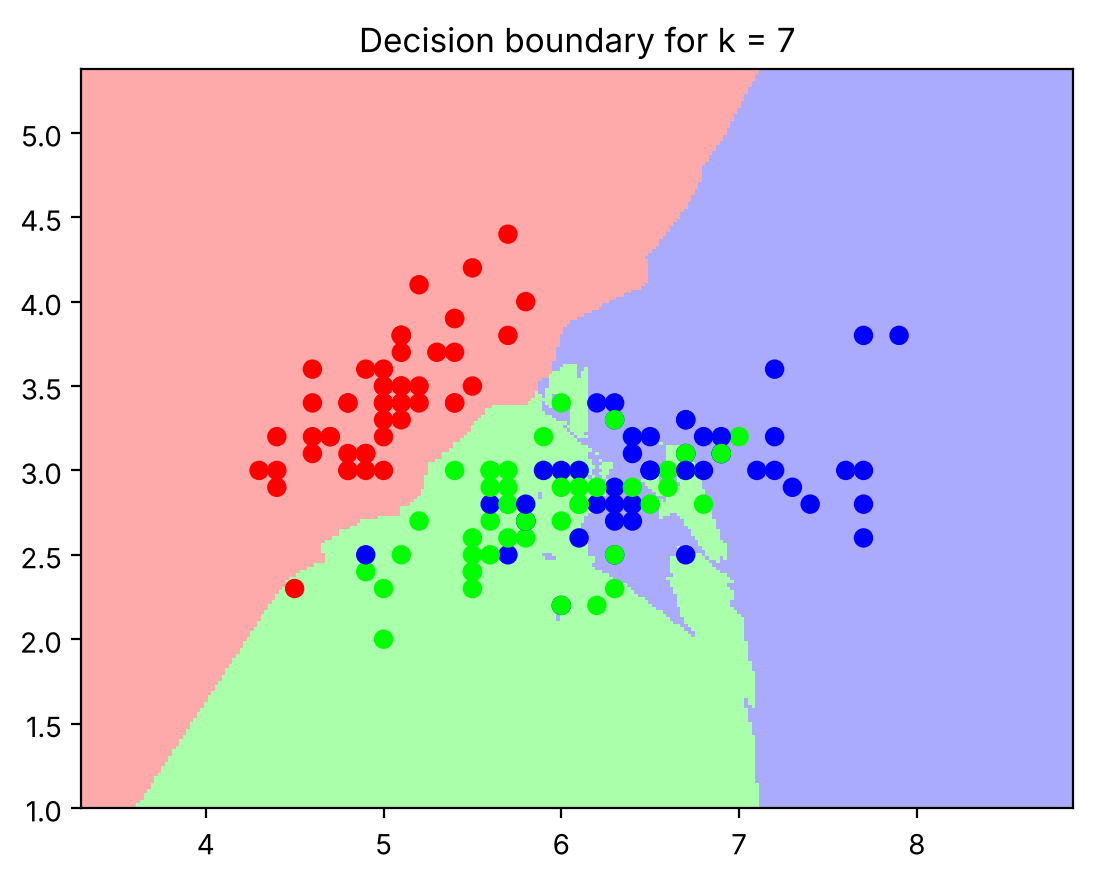

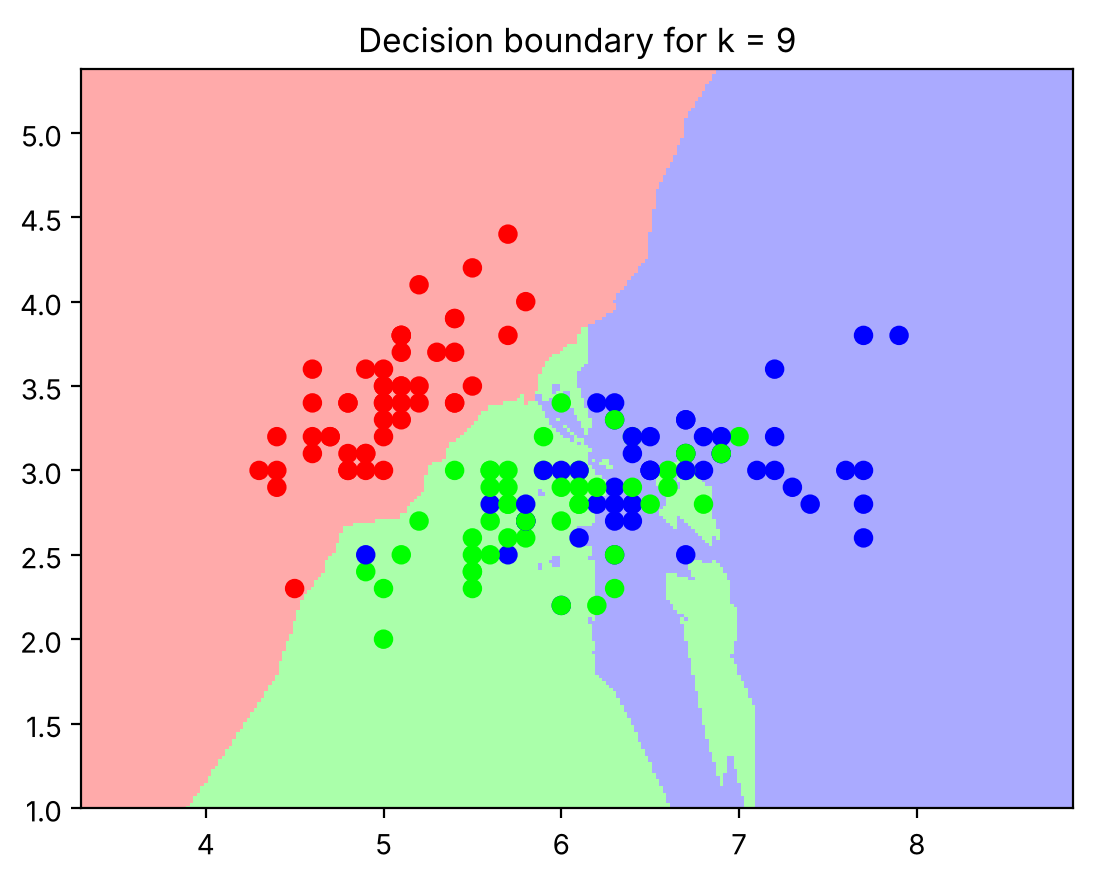

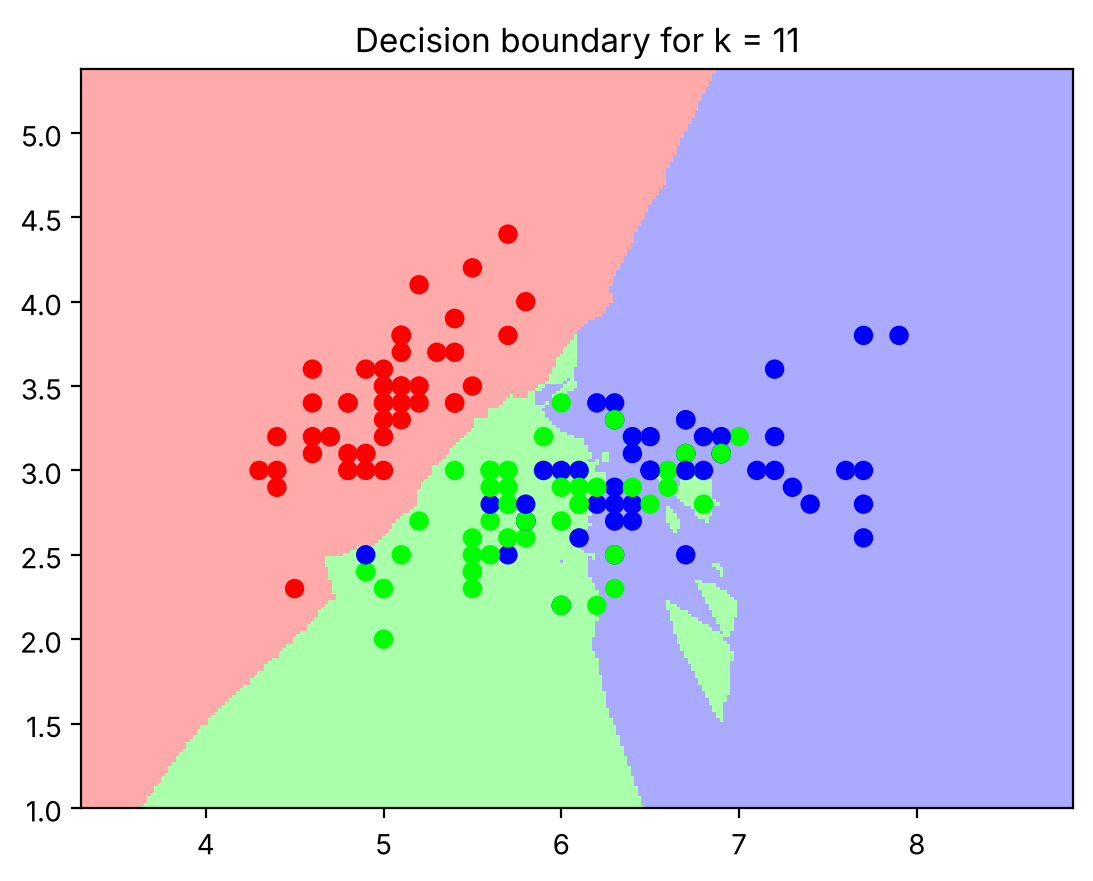

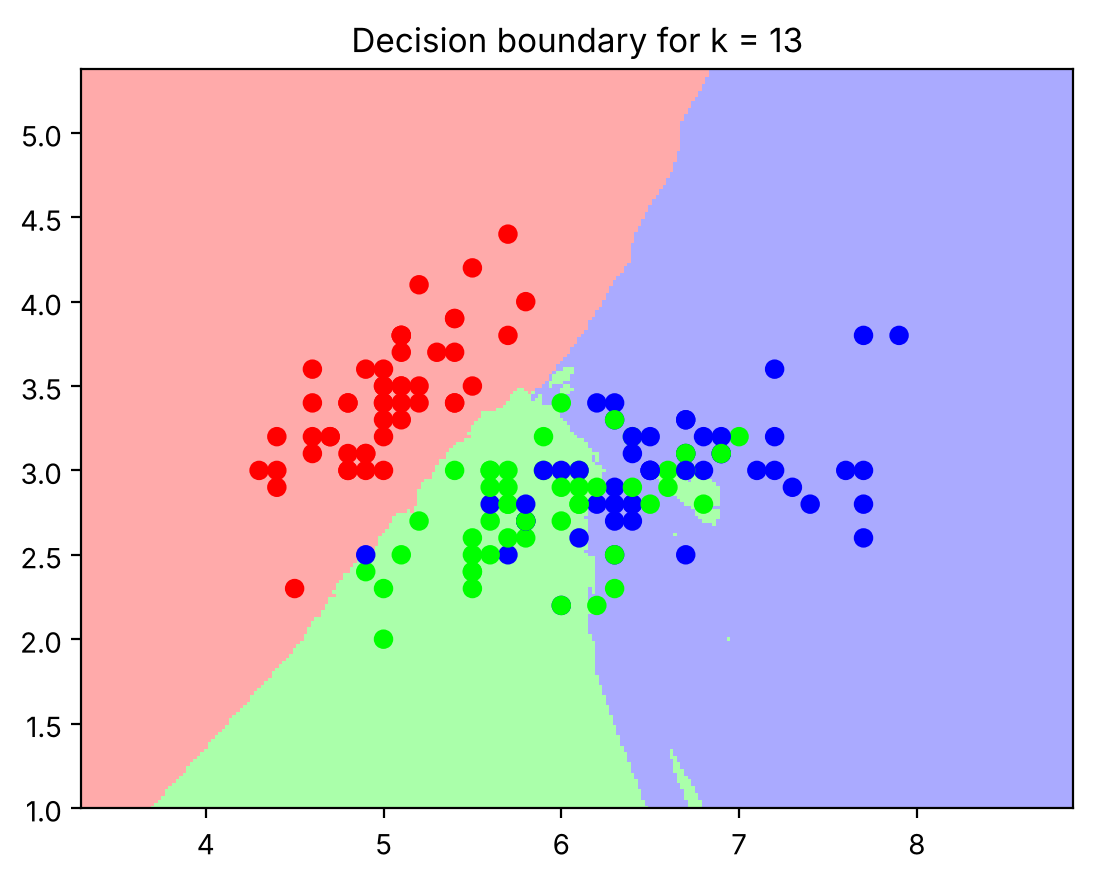

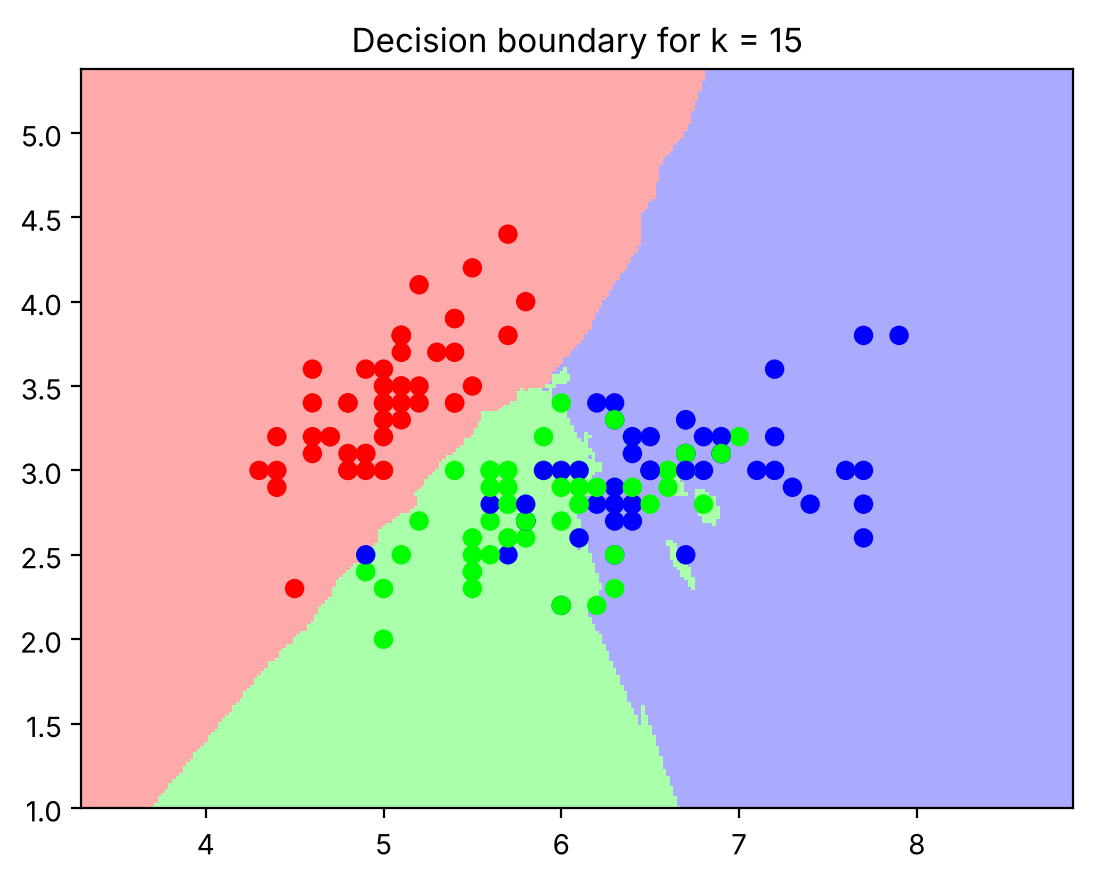

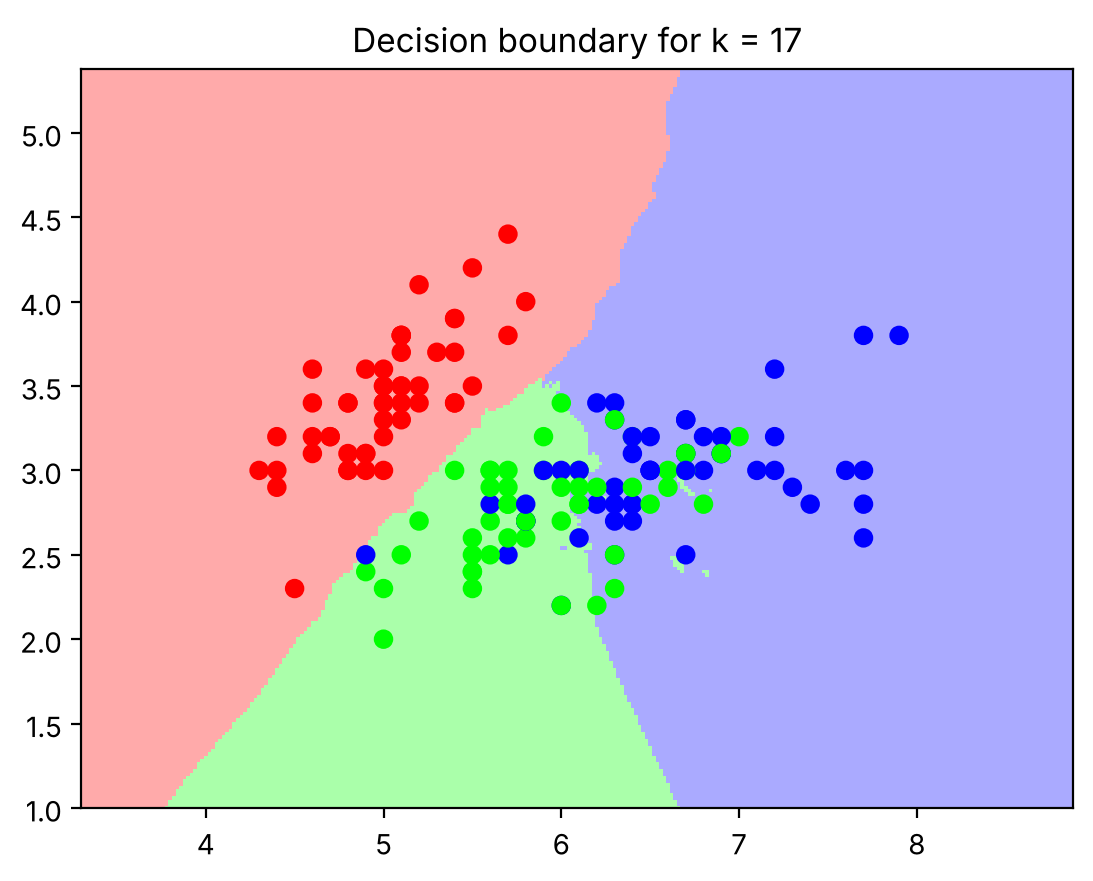

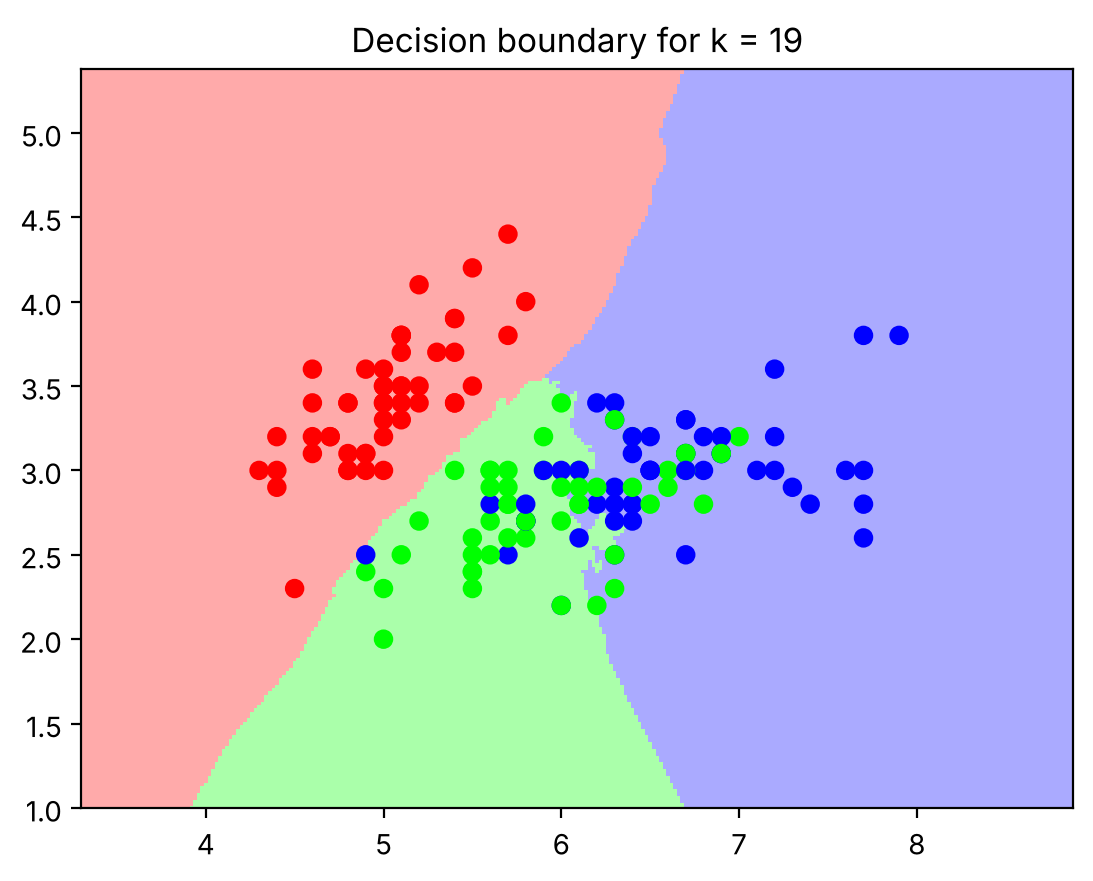

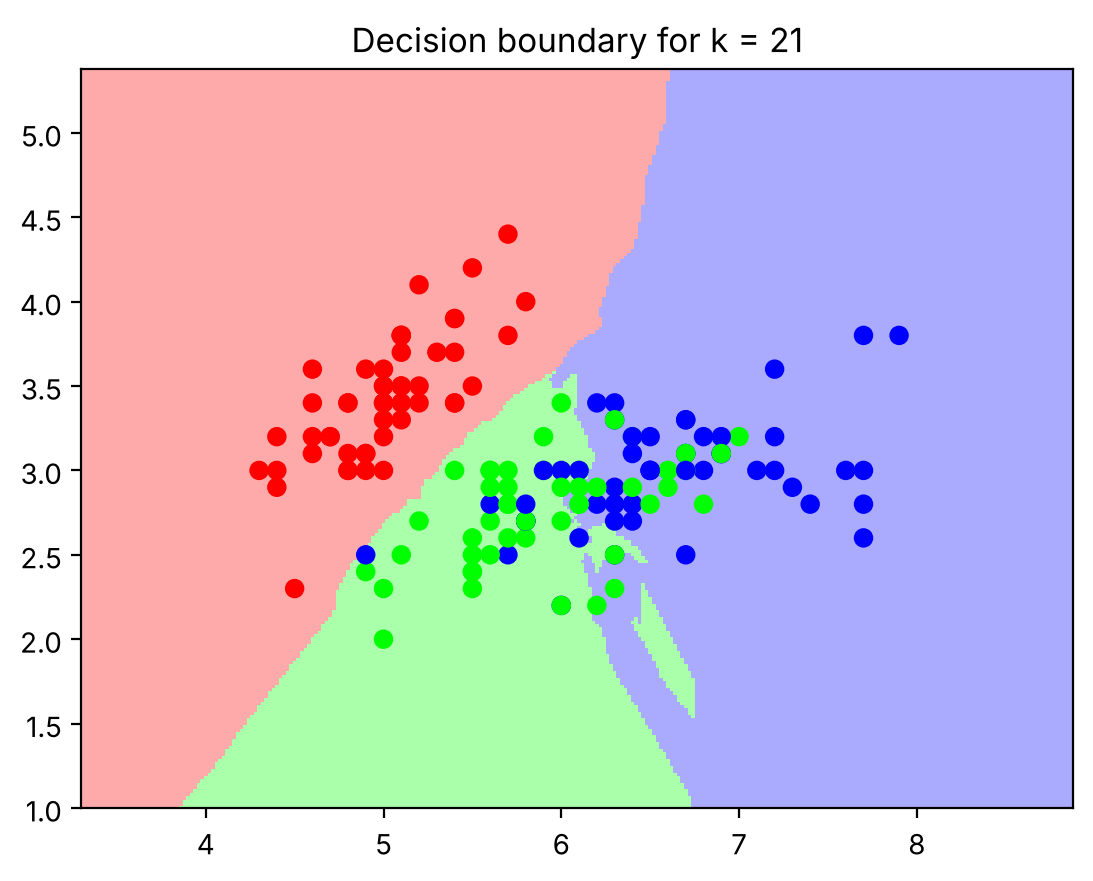

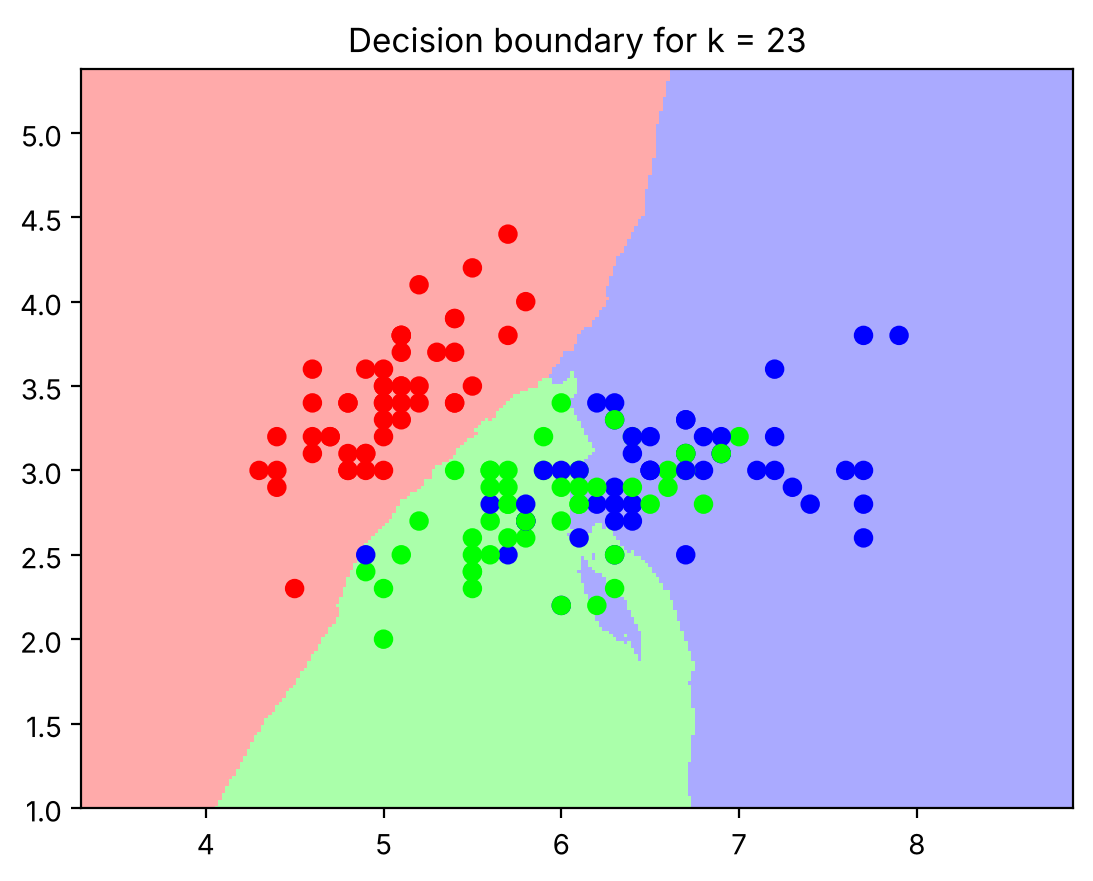

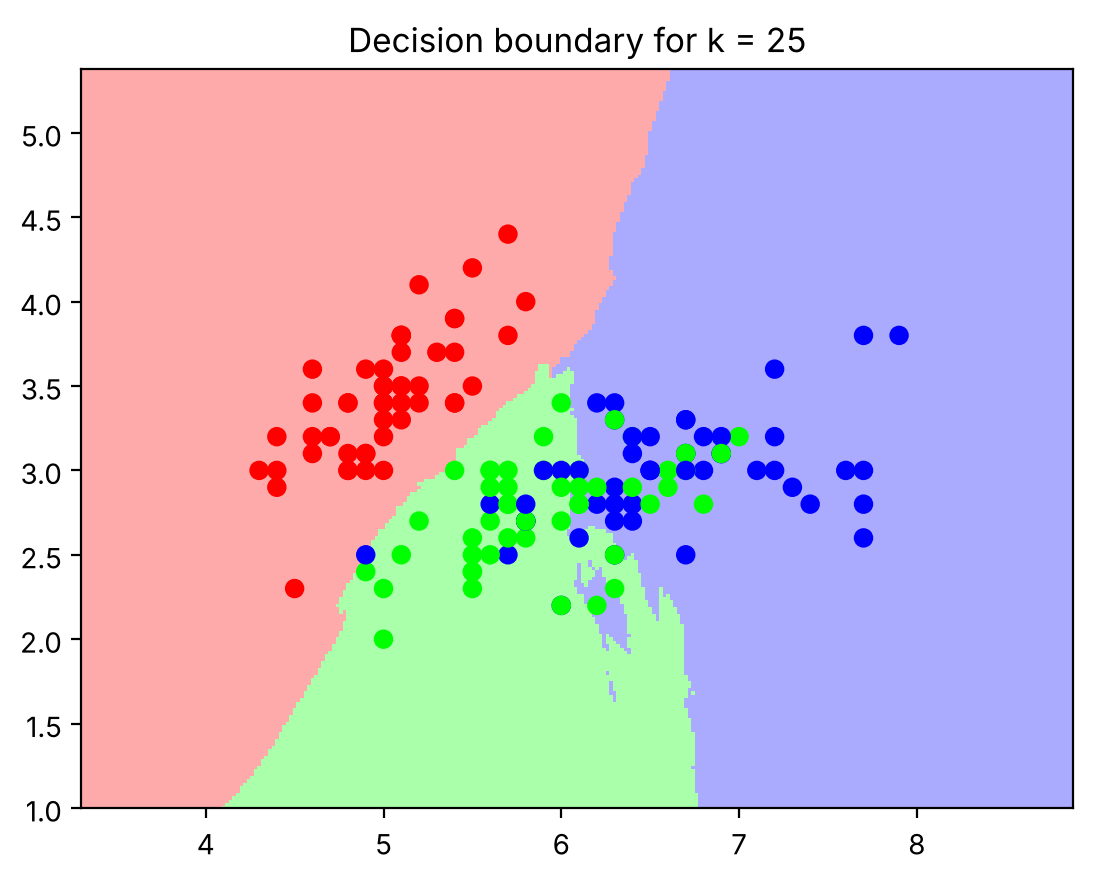

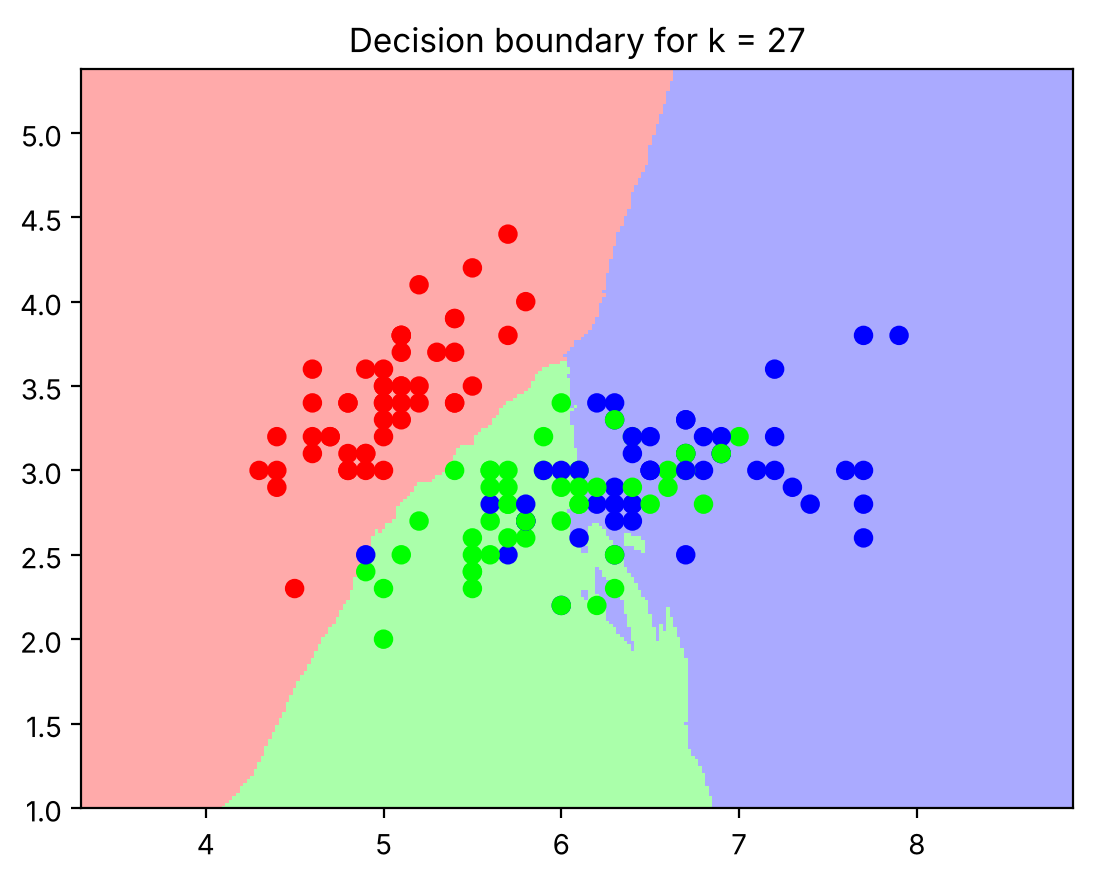

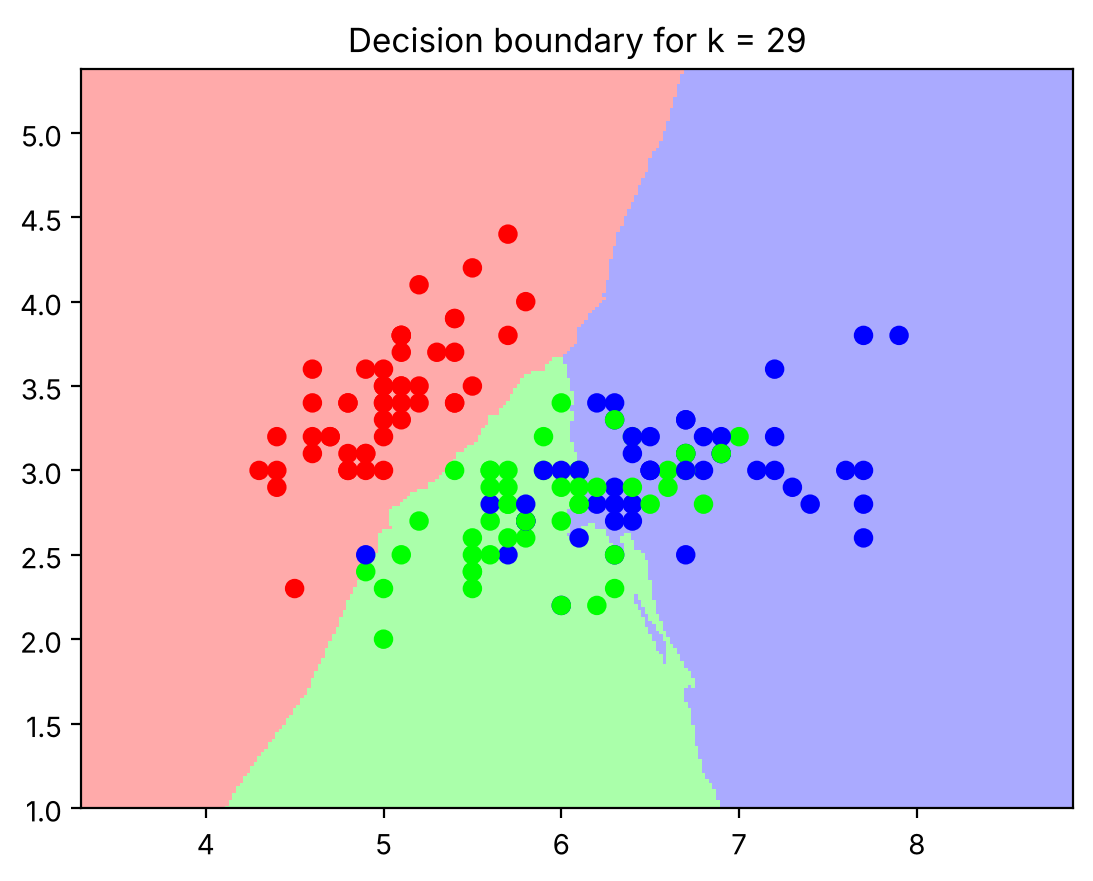

In [10]:
# This code may take several minutes to finish
for k in k_list:
    decision_boundary(k)

# Distance Measures

When using the k-Nearest Neighbors (k-NN) algorithm, selecting an appropriate distance measure is crucial as it affects how "closeness" between data points is defined. Different distance measures are used depending on the nature of the data and the problem you're trying to solve. Here, we'll explore four common distance measures:

## Euclidean Distance

Euclidean distance is the most widely used distance measure. It calculates the straight-line distance between two points in the feature space. For two points, $\mathbf{p} = (x_1, y_1, z_1, \ldots)$ and $\mathbf{q} = (x_2, y_2, z_2, \ldots)$, Euclidean distance is calculated as:


$ d_{\text{Euclidean}}(\mathbf{p}, \mathbf{q}) = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2 + (z_2 - z_1)^2 + \ldots} $


It measures the "as-the-crow-flies" distance and works well for continuous data.

## Manhattan Distance

Manhattan distance, also known as L1 distance, calculates the sum of absolute differences between the coordinates of two points. It is especially suitable for data with a grid-like structure, such as grids or city block layouts. For points A and B, it is computed as:

$ d_{\text{Manhattan}}(\mathbf{p}, \mathbf{q}) = |x_2 - x_1| + |y_2 - y_1| + |z_2 - z_1| + \ldots  $

## Minkowski Distance

Minkowski distance is a generalized distance measure that includes Euclidean and Manhattan distances as special cases. It's controlled by a parameter 'p,' and for 'p' equal to 1, it becomes the Manhattan distance, while for 'p' equal to 2, it's the Euclidean distance. The formula is:

$ d_{\text{Minkowski}}(\mathbf{p}, \mathbf{q}, p) = \left(\sum_{i=1}^{n} |p_i - q_i|^p\right)^{\frac{1}{p}}  $

The choice of 'p' allows you to adjust the sensitivity to different features and data distributions.

## Task 1 [60 marks]

In the previous exercise, we utilised the Euclidean distance measure to calculate the distances between test samples and their neighbors. Now, let's explore the impact of alternative distance measures, specifically Minkowski (with a 'p' value of 3) and Manhattan distances, on our results. In your report, follow these steps:

1. Implement the necessary code to compute Minkowski and Manhattan distances.

2. Keep the same 'k' values used in the previous code to to get the accuracy results of the distance measures used.

3. Create a table that display the accuracy results for each distance measure and 'k' value.

4. Provide a thoughtful discussion of your findings, including any differences observed in the results and their potential implications.



In [11]:
# Task 1.1 - Manhattan and Minkowski distance functions

def manhattan_distance(p1, p2):
    """L1 distance: sum of absolute differences."""
    total = 0.0
    for i in range(len(p1)):
        total += abs(p1[i] - p2[i])
    return total


def minkowski_distance(p1, p2, p=3):
    """Minkowski distance of order p (p=1 -> Manhattan, p=2 -> Euclidean)."""
    total = 0.0
    for i in range(len(p1)):
        total += abs(p1[i] - p2[i]) ** p
    return total ** (1.0 / p)


def fit_with_distance(test_sample, training_set, training_labels, k, distance_fn):
    """Same as fit(), but the distance measure is passed in as a function."""
    distances = []
    for i in range(len(training_set)):
        d = distance_fn(test_sample, training_set[i])
        distances.append([d, training_set[i], training_labels[i]])
    distances.sort(key=lambda x: x[0])

    k_nearest_neighbours = distances[0:k]

    # Majority vote (same tie-breaking rule as the original fit())
    label_counts = {}
    for i in range(0, k):
        closest_label = k_nearest_neighbours[i][2]
        if closest_label in label_counts:
            label_counts[closest_label] += 1
        else:
            label_counts[closest_label] = 1

    labelCounts = list(label_counts.values())
    classes = list(label_counts.keys())
    y_pred = classes[labelCounts.index(max(labelCounts))]
    return (k_nearest_neighbours, y_pred)


# Quick sanity check on two simple points
a, b = [0, 0], [3, 4]
print("Euclidean :", distance(a, b))            # 5.0
print("Manhattan :", manhattan_distance(a, b))  # 7.0
print("Minkowski (p=3):", round(minkowski_distance(a, b, 3), 4))  # ~4.4979


Euclidean : 5.0
Manhattan : 7.0
Minkowski (p=3): 4.4979


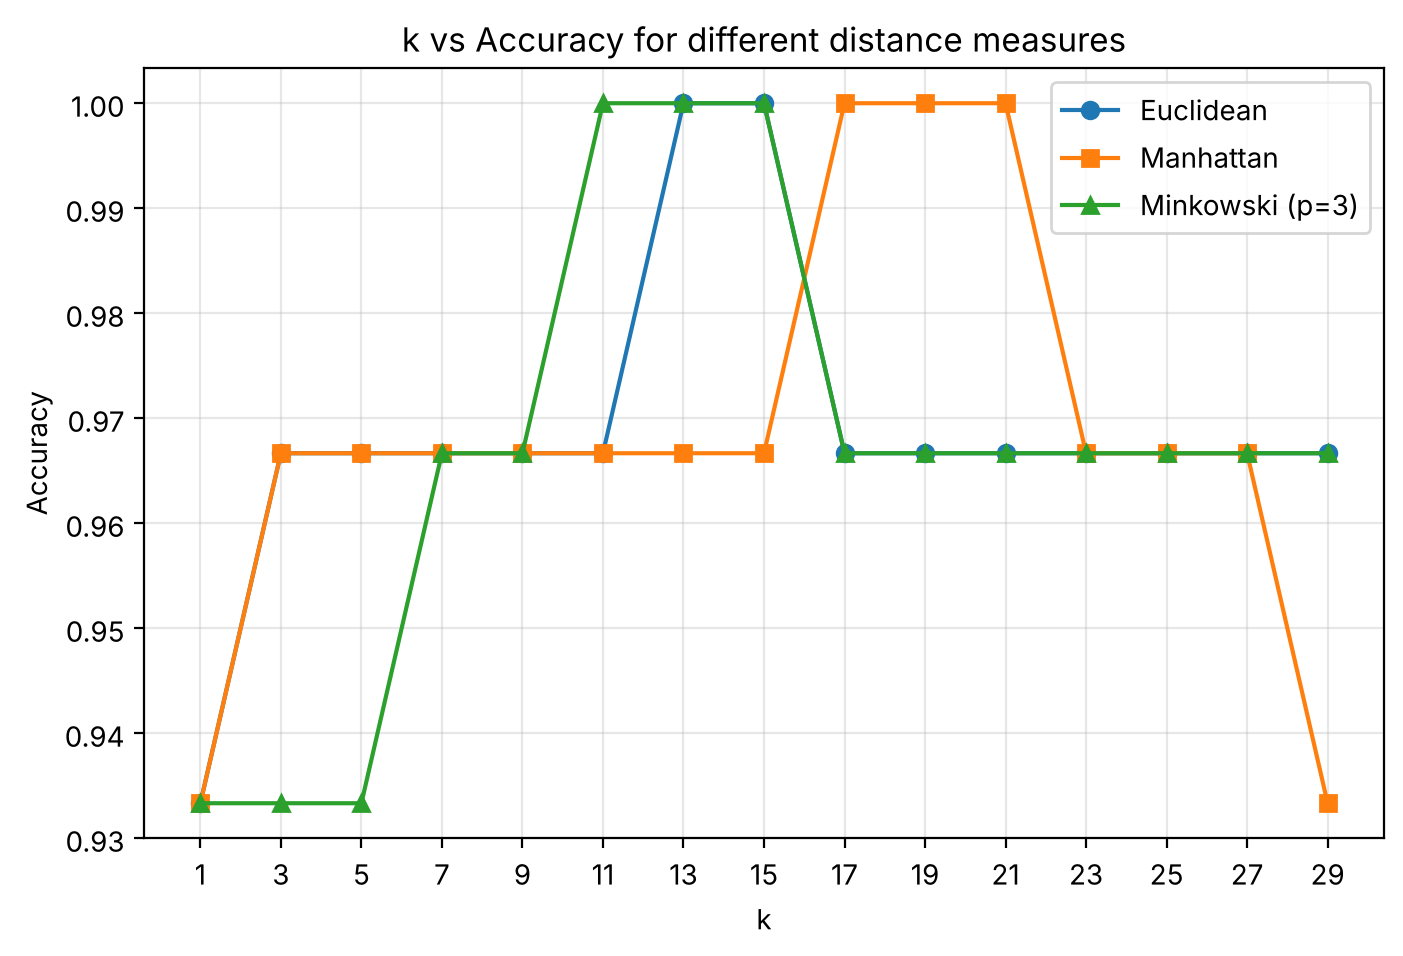

In [12]:
# Task 1.2 - Accuracy for each distance measure using the same k values

distance_measures = {
    'Euclidean': distance,
    'Manhattan': manhattan_distance,
    'Minkowski (p=3)': lambda p1, p2: minkowski_distance(p1, p2, p=3),
}

results_task1 = {name: [] for name in distance_measures}

for name, dist_fn in distance_measures.items():
    for k in k_list:
        y_pred = []
        for test_instance in X_test:
            _, pred_label = fit_with_distance(test_instance, X_train, y_train, k, dist_fn)
            y_pred.append(pred_label)
        results_task1[name].append(accuracy(y_pred, y_test))

# Plot accuracy vs k for each distance measure
plt.figure(figsize=(8, 5))
markers = ['o', 's', '^']
for (name, accs), m in zip(results_task1.items(), markers):
    plt.plot(k_list, accs, marker=m, label=name)
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('k vs Accuracy for different distance measures')
plt.xticks(k_list)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:
# Task 1.3 - Table of accuracy (%) for each distance measure and k

task1_table = pd.DataFrame(results_task1, index=k_list) * 100
task1_table.index.name = 'k'
task1_table = task1_table.round(2)

print("Accuracy (%) on the test set")
display(task1_table)

print("\nMean accuracy (%) across all k:")
print(task1_table.mean().round(2).to_string())


Accuracy (%) on the test set


,Euclidean,Manhattan,Minkowski (p=3)
k,,,
1,93.33,93.33,93.33
3,96.67,96.67,93.33
5,96.67,96.67,93.33
7,96.67,96.67,96.67
9,96.67,96.67,96.67
11,96.67,96.67,100.00
13,100.00,96.67,100.00
15,100.00,96.67,100.00
17,96.67,100.00,96.67



Mean accuracy (%) across all k:
Euclidean          96.89
Manhattan          96.89
Minkowski (p=3)    96.67


### Task 1.4 – Discussion

**Overall performance.** All three distance measures do very well on this split of the Iris data. Accuracy ranges from 93.33 % to 100 %. The test set has only 30 samples, so each misclassified flower costs 3.33 percentage points. In practice the measures differ by **no more than one misclassified sample** at any value of `k`. Averaged over all `k`, Euclidean and Manhattan both reach 96.89 % and Minkowski (p = 3) reaches 96.67 %, which is effectively the same.

**Where the measures differ.**
- At `k = 1` all three get 93.33 %. Using a single neighbour makes the classifier sensitive to individual points near the class boundary, whatever distance is used.
- For small `k` (3–5), Minkowski (p = 3) misclassifies one more sample than the other two. A higher `p` puts more weight on the single feature with the largest difference, so it can pick a different set of nearest neighbours for points near the Versicolor/Virginica overlap.
- Each measure reaches 100 % on a different range of `k`: Minkowski at k = 11–15, Euclidean at k = 13–15 and Manhattan at k = 17–21. Changing the metric changes the shape of the neighbourhood (a diamond for L1, a circle for L2, a more square-like shape for p = 3), so the best `k` depends on the metric.
- At large `k` (≥ 23), Euclidean and Minkowski settle at 96.67 %. Manhattan drops to 93.33 % at `k = 29`. With 120 training samples (40 per class), a neighbourhood of 29 points starts to take in many samples from the neighbouring class.

**Implications.**
- On a small, clean, low-dimensional dataset like Iris, the choice of distance measure matters less than the choice of `k`. Both choices affect performance by only one or two test samples here.
- With such a small test set, these differences are **not statistically meaningful**. A single split cannot show that one metric is better than another. Cross-validation (for example k-fold) would give a more reliable comparison and a better way to choose `k` and the metric together.
- The features were not scaled. Petal length has a much larger range than petal or sepal width, so it dominates all three distances, and more so as `p` increases. Standardising the features would give each feature a fairer weight and could change the ranking of the metrics.
- Manhattan distance is generally less affected by a large difference in one feature (outliers) and tends to hold up better in higher-dimensional data. Higher `p` behaves more like the Chebyshev (maximum) distance. These effects are small on 4-feature Iris but become more important on larger or noisier datasets.


# Scikit-learn Implementation

Scikit-learn provides a convenient and user-friendly way to do so. First, you'll need to import the necessary module:
```python
from sklearn.neighbors import KNeighborsClassifier
```

You can initialise the classifier with various parameters:
> More information can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)


> More information on distacnce measures using scikit-learn can be found [here](https://scikit-learn.org/0.24/modules/generated/sklearn.neighbors.DistanceMetric.html)



## Task 2 [40 marks]

In this task, your objective is to replicate the procedure outlined in the tutorial using Scikit-Learn for the k-Nearest Neighbors (k-NN) algorithm. Follow these steps and include your findings in your report:

1. Write Python code using Scikit-Learn to perform k-NN as demonstrated in the tutorial.

2. Generate a table that compares the accuracy results from Task1 with the ones obtained using Scikit-Learn for different distance measures and 'k' values.


In [14]:
# Task 2 - k-NN using scikit-learn
from sklearn.neighbors import KNeighborsClassifier

sk_settings = {
    'Euclidean': dict(metric='minkowski', p=2),
    'Manhattan': dict(metric='minkowski', p=1),
    'Minkowski (p=3)': dict(metric='minkowski', p=3),
}

results_sklearn = {name: [] for name in sk_settings}

for name, params in sk_settings.items():
    for k in k_list:
        knn = KNeighborsClassifier(n_neighbors=k, algorithm='brute', **params)
        knn.fit(X_train, y_train)
        y_pred_sk = knn.predict(X_test)
        results_sklearn[name].append(accuracy(y_pred_sk, y_test))

# Comparison table: our implementation (Task 1) vs scikit-learn
columns = {}
for name in sk_settings:
    columns[(name, 'Task 1')] = np.array(results_task1[name]) * 100
    columns[(name, 'scikit-learn')] = np.array(results_sklearn[name]) * 100

comparison_table = pd.DataFrame(columns, index=k_list).round(2)
comparison_table.columns = pd.MultiIndex.from_tuples(comparison_table.columns,
                                                     names=['Distance', 'Implementation'])
comparison_table.index.name = 'k'

print("Accuracy (%) - own implementation vs scikit-learn")
display(comparison_table)

# Flag any k where the two implementations disagree
for name in sk_settings:
    diff = [k for k, a, b in zip(k_list, results_task1[name], results_sklearn[name]) if not np.isclose(a, b)]
    if diff:
        print(f"{name}: results differ for k = {diff}")
    else:
        print(f"{name}: identical accuracy for every k")


Accuracy (%) - own implementation vs scikit-learn


Distance       Euclidean              Manhattan              Minkowski (p=3)  \
Implementation    Task 1 scikit-learn    Task 1 scikit-learn          Task 1   
k                                                                              
1                  93.33        93.33     93.33        93.33           93.33   
3                  96.67        96.67     96.67        96.67           93.33   
5                  96.67        96.67     96.67        96.67           93.33   
7                  96.67        96.67     96.67        96.67           96.67   
9                  96.67        96.67     96.67        96.67           96.67   
11                 96.67        96.67     96.67        96.67          100.00   
13                100.00       100.00     96.67        96.67          100.00   
15                100.00       100.00     96.67        96.67          100.00   
17                 96.67        96.67    100.00       100.00           96.67   
19                 96.67        96.67    100.00       100.00           96.67   
21                 96.67        96.67    100.00       100.00           96.67   
23                 96.67        96.67     96.67        96.67           96.67   
25                 96.67        96.67     96.67        96.67           96.67   
27                 96.67        96.67     96.67        96.67           96.67   
29                 96.67        96.67     93.33        93.33           96.67   

Distance                     
Implementation scikit-learn  
k                            
1                     93.33  
3                     93.33  
5                     93.33  
7                     96.67  
9                     96.67  
11                   100.00  
13                   100.00  
15                   100.00  
17                    96.67  
19                    96.67  
21                    96.67  
23                    96.67  
25                    96.67  
27                    96.67  
29                    96.67

Euclidean: identical accuracy for every k
Manhattan: identical accuracy for every k
Minkowski (p=3): identical accuracy for every k


### Task 2 – Discussion

The scikit-learn `KNeighborsClassifier` gives **exactly the same accuracy** as the from-scratch implementation for every distance measure and every value of `k`. This confirms that the Manhattan and Minkowski functions and the majority-vote logic in Task 1 are correct.

In scikit-learn, the distance measure is set with `metric='minkowski'` and the parameter `p`: `p=1` gives Manhattan, `p=2` gives Euclidean and `p=3` gives Minkowski (p = 3). `algorithm='brute'` makes scikit-learn compare against every training point, as our own `fit()` does. Its default (`'auto'`) would use a KD-tree or ball-tree to find the neighbours faster, which should give the same neighbours on this data.

The two implementations could in principle differ when a vote is tied. Our function picks the tied class that appears first among the sorted neighbours. scikit-learn picks the class with the lowest label. No such tie affected the results here. The scikit-learn version is also much faster because it runs vectorised, compiled code instead of Python loops.
